# First try a entrenar la ResNet amb la training data de DENTEX

In [1]:
from pathlib import Path
import json

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

## Inserint validació i entrenament (json e img)

In [2]:
data_dir = Path("data/raw/dentex")

val_images_dir = (
    data_dir
    / "validation_data"
    / "quadrant_enumeration_disease"
    / "xrays"
)

train_images_dir = (
    data_dir / "training_data" / "quadrant-enumeration-disease" / "xrays"

)

VAL_json_path = data_dir / "validation_triple.json"
train_json_path = data_dir / "training_data" / "quadrant-enumeration-disease" / "train_quadrant_enumeration_disease.json"


with open(VAL_json_path, "r") as f:
    VAL_data = json.load(f)

with open(train_json_path, "r") as f:
    train_data = json.load(f)


print(f"Imatges: {len(VAL_data['images'])}")
print(f"Anotacions: {len(VAL_data['annotations'])}")
print(VAL_data.keys())

print(f"Imatges: {len(train_data['images'])}")
print(f"Anotacions: {len(train_data['annotations'])}")
print(train_data.keys())

#definim les patologies en diccionaris (en aquest cas de validació)

quadrants = {x["id"]: x["name"] for x in VAL_data["categories_1"]}
teeth = {x["id"]: x["name"] for x in VAL_data["categories_2"]}
diagnoses = {x["id"]: x["name"] for x in VAL_data["categories_3"]}



Imatges: 50
Anotacions: 182
dict_keys(['images', 'annotations', 'categories_1', 'categories_2', 'categories_3'])
Imatges: 705
Anotacions: 3529
dict_keys(['images', 'annotations', 'categories_1', 'categories_2', 'categories_3'])


## Fem els dataframes per val i per train

In [3]:
import pandas as pd

# Fila per cada imatge
labels_df = pd.DataFrame(train_data["images"])[["id", "file_name","height", "width"]]
#canviarem el nom de id, per image_id, per a que sigui més clar
labels_df.rename(columns = {"id": "image_id"}, inplace = True)

print(labels_df.head())# Ara definim les etiquetes de les patologies

label_names = {
    0: "has_impacted",
    1: "has_caries",
    2: "has_periapical_lesion",
    3: "has_deep_caries"
}

for label in label_names.values():
    labels_df[label] = 0


#i ara hem d'omplir les etiquetes cada cop que tenim el diagnostic corresponent
# només m'interessa la categoria 3, que és la que ens diu quina patologia és

for ann in train_data["annotations"]:
    image_id = ann["image_id"]
    diagnosis_id = ann["category_id_3"]
    label_name = label_names[diagnosis_id]
    labels_df.loc[labels_df["image_id"] == image_id, label_name] = 1

# i ara per validation


labels_val_df = pd.DataFrame(VAL_data["images"])[["id", "file_name","height", "width"]]
#canviarem el nom de id, per image_id, per a que sigui més clar
labels_val_df.rename(columns = {"id": "image_id"}, inplace = True)

print(labels_val_df.head())# Ara definim les etiquetes de les patologies

for label in label_names.values():
    labels_val_df[label] = 0


#i ara hem d'omplir les etiquetes cada cop que tenim el diagnostic corresponent
# només m'interessa la categoria 3, que és la que ens diu quina patologia és

for ann in VAL_data["annotations"]:
    image_id = ann["image_id"]
    diagnosis_id = ann["category_id_3"]
    label_name = label_names[diagnosis_id]
    labels_val_df.loc[labels_val_df["image_id"] == image_id, label_name] = 1

labels_val_df.head(10)
labels_df.head(10)

   image_id      file_name  height  width
0         1  train_673.png    1316   2744
1         2  train_283.png    1504   2872
2         3  train_435.png    1316   2909
3         4   train_95.png    1504   2872
4         5  train_475.png    1504   2872
   image_id   file_name  height  width
0         1  val_15.png    1316   2892
1         2  val_38.png    1316   2942
2         3  val_33.png    1316   2987
3         4  val_30.png    1504   2872
4         5   val_5.png    1316   2970


,image_id,file_name,height,width,has_impacted,has_caries,has_periapical_lesion,has_deep_caries
0,1,train_673.png,1316,2744,1,1,1,0
1,2,train_283.png,1504,2872,1,1,0,0
2,3,train_435.png,1316,2909,0,0,0,0
3,4,train_95.png,1504,2872,0,1,1,1
4,5,train_475.png,1504,2872,0,0,1,1
5,6,train_62.png,1316,2867,0,1,0,1
6,7,train_637.png,1536,3076,0,1,0,1
7,8,train_187.png,1316,2815,1,1,1,1
8,9,train_509.png,1316,2928,1,1,1,1
9,10,train_31.png,1504,2872,0,1,0,0


### Comprobem si les dades estan totes bé. 

In [4]:
diagnosis_columns = [
    "has_impacted",
    "has_caries",
    "has_periapical_lesion",
    "has_deep_caries",
]

print("TRAIN")
print("Nombre d'imatges:", len(labels_df))
display(labels_df[diagnosis_columns].sum())

print("\nVALIDATION")
print("Nombre d'imatges:", len(labels_val_df))
display(labels_val_df[diagnosis_columns].sum())

TRAIN
Nombre d'imatges: 705


has_impacted             254
has_caries               623
has_periapical_lesion    116
has_deep_caries          321
dtype: int64


VALIDATION
Nombre d'imatges: 50


has_impacted             16
has_caries               37
has_periapical_lesion     7
has_deep_caries          20
dtype: int64

### Has_impacted test

In [5]:
print("TRAIN — dents impactades")
display(labels_df["has_impacted"].value_counts())

print("VALIDATION — dents impactades")
display(labels_val_df["has_impacted"].value_counts())

TRAIN — dents impactades


has_impacted
0    451
1    254
Name: count, dtype: int64

VALIDATION — dents impactades


has_impacted
0    34
1    16
Name: count, dtype: int64

In [6]:
assert set(labels_df["has_impacted"].unique()) <= {0, 1}
assert set(labels_val_df["has_impacted"].unique()) <= {0, 1}
assert labels_df["has_impacted"].isna().sum() == 0
assert labels_val_df["has_impacted"].isna().sum() == 0


print(train_images_dir / labels_df.iloc[0]["file_name"])
print(val_images_dir / labels_val_df.iloc[0]["file_name"])

data\raw\dentex\training_data\quadrant-enumeration-disease\xrays\train_673.png
data\raw\dentex\validation_data\quadrant_enumeration_disease\xrays\val_15.png


data\raw\dentex\training_data\quadrant-enumeration-disease\xrays\train_673.png


data\raw\dentex\validation_data\quadrant_enumeration_disease\xrays\val_15.png

# Comencem a entrenar les imatges i a fer el model 

In [7]:
class OPGDataset(Dataset):
    def __init__(self, labels_df, images_dir, transform=None):
        self.labels_df = labels_df.reset_index(drop=True)
        self.images_dir = Path(images_dir)
        self.transform = transform

    def __len__(self):
        return len(self.labels_df)

    def __getitem__(self, index):
        row = self.labels_df.iloc[index]

        # Carrega l'orto i la passa a RGB:
        # visualment continuarà sent grisa, però tindrà 3 canals,
        # que és el format que espera la ResNet preentrenada.
        image_path = self.images_dir / row["file_name"]
        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        # Etiqueta binària: 0 = no impactada, 1 = impactada
        target = torch.tensor(row["has_impacted"], dtype=torch.long)

        return image, target

Les transformacions per a normalitzar les imatges

In [8]:
train_transform = transforms.Compose([
    transforms.Resize((256, 512)),
    transforms.RandomAffine(
        degrees=3,
        translate=(0.02, 0.02),
        scale=(0.95, 1.05)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((256, 512)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

## Ara la capa final del model

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # per a correr el model

import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False



# carregat amb les imatges de ImageNet

model = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

# Congela totes les capes ja preentrenades
for parameter in model.parameters():
    parameter.requires_grad = False

# Substitueix el classificador ImageNet de 1.000 classes
# per un classificador de 2 classes: no impactada / impactada
num_features = model.fc.in_features
model.fc = torch.nn.Linear(num_features, 2)

model = model.to(device)

## i definim la loss

In [10]:
import torch.nn as nn


n_negative = (labels_df["has_impacted"] == 0).sum()
n_positive = (labels_df["has_impacted"] == 1).sum()
n_total = len(labels_df)

class_weights = torch.tensor(
    [
        n_total / (2 * n_negative),
        n_total / (2 * n_positive)
    ],
    dtype=torch.float32,
    device=device
)

print("Pes classe 0:", class_weights[0].item())
print("Pes classe 1:", class_weights[1].item())

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

Pes classe 0: 0.7815964818000793
Pes classe 1: 1.387795329093933


## Ara ja cridem a les funcions que toquen 

In [11]:
from torch.utils.data import DataLoader

train_dataset = OPGDataset(
    labels_df,
    train_images_dir,
    transform=train_transform
)

val_dataset = OPGDataset(
    labels_val_df,
    val_images_dir,
    transform=val_transform
)

batch_size = 8

#ara amb el dataloader li tirem els datasets
#només shuflejem el train

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,      # canvia l'ordre a cada època
    num_workers=0      # opció segura per Windows + notebook
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,     # validació sempre en ordre estable
    num_workers=0
)

In [12]:
images, targets = next(iter(train_loader))

print("Forma del batch:", images.shape)
print("Etiquetes:", targets)

Forma del batch: torch.Size([8, 3, 256, 512])
Etiquetes: tensor([1, 0, 0, 1, 1, 1, 0, 0])


# I ara entrenem

Probem a guardar el de menor val_loss

In [13]:
from pathlib import Path

#num_epochs = 8
#best_val_accuracy = 0.0

num_epochs = 8
best_val_loss = float("inf")
best_epoch = None

checkpoint_path = "models/resnet18_impacted_weighted_feature_ext.pt"

Path("models").mkdir(exist_ok=True)

for epoch in range(num_epochs):

    # -------- we TRAIN the model --------
    #model.train()
    model.eval()       # manté fixes les estadístiques de BatchNorm
    model.fc.train()   # capa final en mode d'entrenament

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, targets in train_loader:
        images = images.to(device)
        targets = targets.to(device)

        # Esborra gradients acumulats del batch anterior
        optimizer.zero_grad()

        # Predicció: dos logits per imatge
        logits = model(images)

        # Compara predicció i etiqueta real
        loss = criterion(logits, targets)

        # Calcula gradients només de l'última capa
        loss.backward()

        # Actualitza els pesos de l'última capa
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        predictions = logits.argmax(dim=1)
        train_correct += (predictions == targets).sum().item()
        train_total += targets.size(0)

    train_loss = train_loss / train_total
    train_accuracy = train_correct / train_total

    # -------- VALIDATION --------
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    # No volem gradients ni actualitzar pesos aquí
    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.to(device)

            logits = model(images)
            loss = criterion(logits, targets)

            val_loss += loss.item() * images.size(0)

            predictions = logits.argmax(dim=1)
            val_correct += (predictions == targets).sum().item()
            val_total += targets.size(0)

    val_loss = val_loss / val_total
    val_accuracy = val_correct / val_total

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"train loss: {train_loss:.4f} | "
        f"train acc: {train_accuracy:.3f} | "
        f"val loss: {val_loss:.4f} | "
        f"val acc: {val_accuracy:.3f}"
    )

    # Desa el millor model segons validació
    #if val_accuracy > best_val_accuracy:
     #   best_val_accuracy = val_accuracy

      #  torch.save(
       #     model.state_dict(),
        #    "models/resnet18_impacted_weighted_feature_ext.pt"
        #)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            checkpoint_path
        )

        print(
            f"  Checkpoint desat: època {best_epoch}, "
            f"val loss = {best_val_loss:.4f}"
        )

Epoch 1/8 | train loss: 0.7025 | train acc: 0.545 | val loss: 0.6799 | val acc: 0.620
  Checkpoint desat: època 1, val loss = 0.6799
Epoch 2/8 | train loss: 0.6890 | train acc: 0.607 | val loss: 0.6780 | val acc: 0.660
  Checkpoint desat: època 2, val loss = 0.6780
Epoch 3/8 | train loss: 0.5986 | train acc: 0.672 | val loss: 0.6805 | val acc: 0.680
Epoch 4/8 | train loss: 0.5857 | train acc: 0.702 | val loss: 0.6876 | val acc: 0.660
Epoch 5/8 | train loss: 0.5581 | train acc: 0.718 | val loss: 0.6987 | val acc: 0.660
Epoch 6/8 | train loss: 0.5652 | train acc: 0.696 | val loss: 0.7538 | val acc: 0.640
Epoch 7/8 | train loss: 0.5605 | train acc: 0.715 | val loss: 0.7038 | val acc: 0.680
Epoch 8/8 | train loss: 0.5558 | train acc: 0.711 | val loss: 0.7729 | val acc: 0.640


In [14]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA de PyTorch:", torch.version.cuda)

PyTorch: 2.11.0+cu128
CUDA disponible: True
GPU: NVIDIA GeForce RTX 5060 Ti
CUDA de PyTorch: 12.8


# Nem a estudiar els resultats

In [15]:
print("Distribució de validation:")
display(labels_val_df["has_impacted"].value_counts())

majority_baseline = (
    labels_val_df["has_impacted"]
    .value_counts(normalize=True)
    .max()
)

print(f"Baseline de la classe majoritària: {majority_baseline:.3f}")



Distribució de validation:


has_impacted
0    34
1    16
Name: count, dtype: int64

Baseline de la classe majoritària: 0.680


Sembla que la millor distribució no és només NO o SI

## Per tant farem una avaluació més complerta

In [17]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

# Reconstrueix la mateixa arquitectura
best_model = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

for parameter in best_model.parameters():
    parameter.requires_grad = False

best_model.fc = nn.Linear(
    best_model.fc.in_features,
    2
)

best_model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only = True
    )
)

best_model = best_model.to(device)
best_model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [18]:
all_targets = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, targets in val_loader:
        images = images.to(device)

        logits = best_model(images)

        # Probabilitat de classe 1: "hi ha dent impactada"
        probabilities = torch.softmax(logits, dim=1)[:, 1]

        # Classe final: 0 o 1
        predictions = logits.argmax(dim=1)

        all_targets.extend(targets.numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

In [19]:
print("Matriu de confusió:")
print(confusion_matrix(all_targets, all_predictions))

print("\nInforme:")
print(
    classification_report(
        all_targets,
        all_predictions,
        target_names=["Sense impactació", "Amb impactació"]
    )
)

print("ROC-AUC:", round(roc_auc_score(all_targets, all_probabilities), 3))
print(
    "Average precision:",
    round(average_precision_score(all_targets, all_probabilities), 3)
)

Matriu de confusió:
[[26  8]
 [ 9  7]]

Informe:
                  precision    recall  f1-score   support

Sense impactació       0.74      0.76      0.75        34
  Amb impactació       0.47      0.44      0.45        16

        accuracy                           0.66        50
       macro avg       0.60      0.60      0.60        50
    weighted avg       0.65      0.66      0.66        50

ROC-AUC: 0.643
Average precision: 0.457


## extra aval i visualització

In [20]:
results_df = labels_val_df[
    ["image_id", "file_name", "has_impacted"]
].copy()

results_df["prob_impacted"] = all_probabilities
results_df["prediction"] = all_predictions

results_df["error_type"] = "Correcte"

results_df.loc[
    (results_df["has_impacted"] == 0)
    & (results_df["prediction"] == 1),
    "error_type"
] = "Fals positiu"

results_df.loc[
    (results_df["has_impacted"] == 1)
    & (results_df["prediction"] == 0),
    "error_type"
] = "Fals negatiu"

errors_df = results_df[
    results_df["error_type"] != "Correcte"
].reset_index(drop=True)

display(
    errors_df.sort_values("prob_impacted")[
        [
            "file_name",
            "has_impacted",
            "prediction",
            "prob_impacted",
            "error_type"
        ]
    ]
)

,file_name,has_impacted,prediction,prob_impacted,error_type
16,val_0.png,1,0,0.110122,Fals negatiu
6,val_37.png,1,0,0.139605,Fals negatiu
10,val_14.png,1,0,0.249136,Fals negatiu
2,val_2.png,1,0,0.319110,Fals negatiu
0,val_15.png,1,0,0.332740,Fals negatiu
11,val_9.png,1,0,0.352099,Fals negatiu
9,val_1.png,1,0,0.405256,Fals negatiu
15,val_12.png,1,0,0.443275,Fals negatiu
5,val_41.png,1,0,0.447387,Fals negatiu
4,val_26.png,0,1,0.505016,Fals positiu


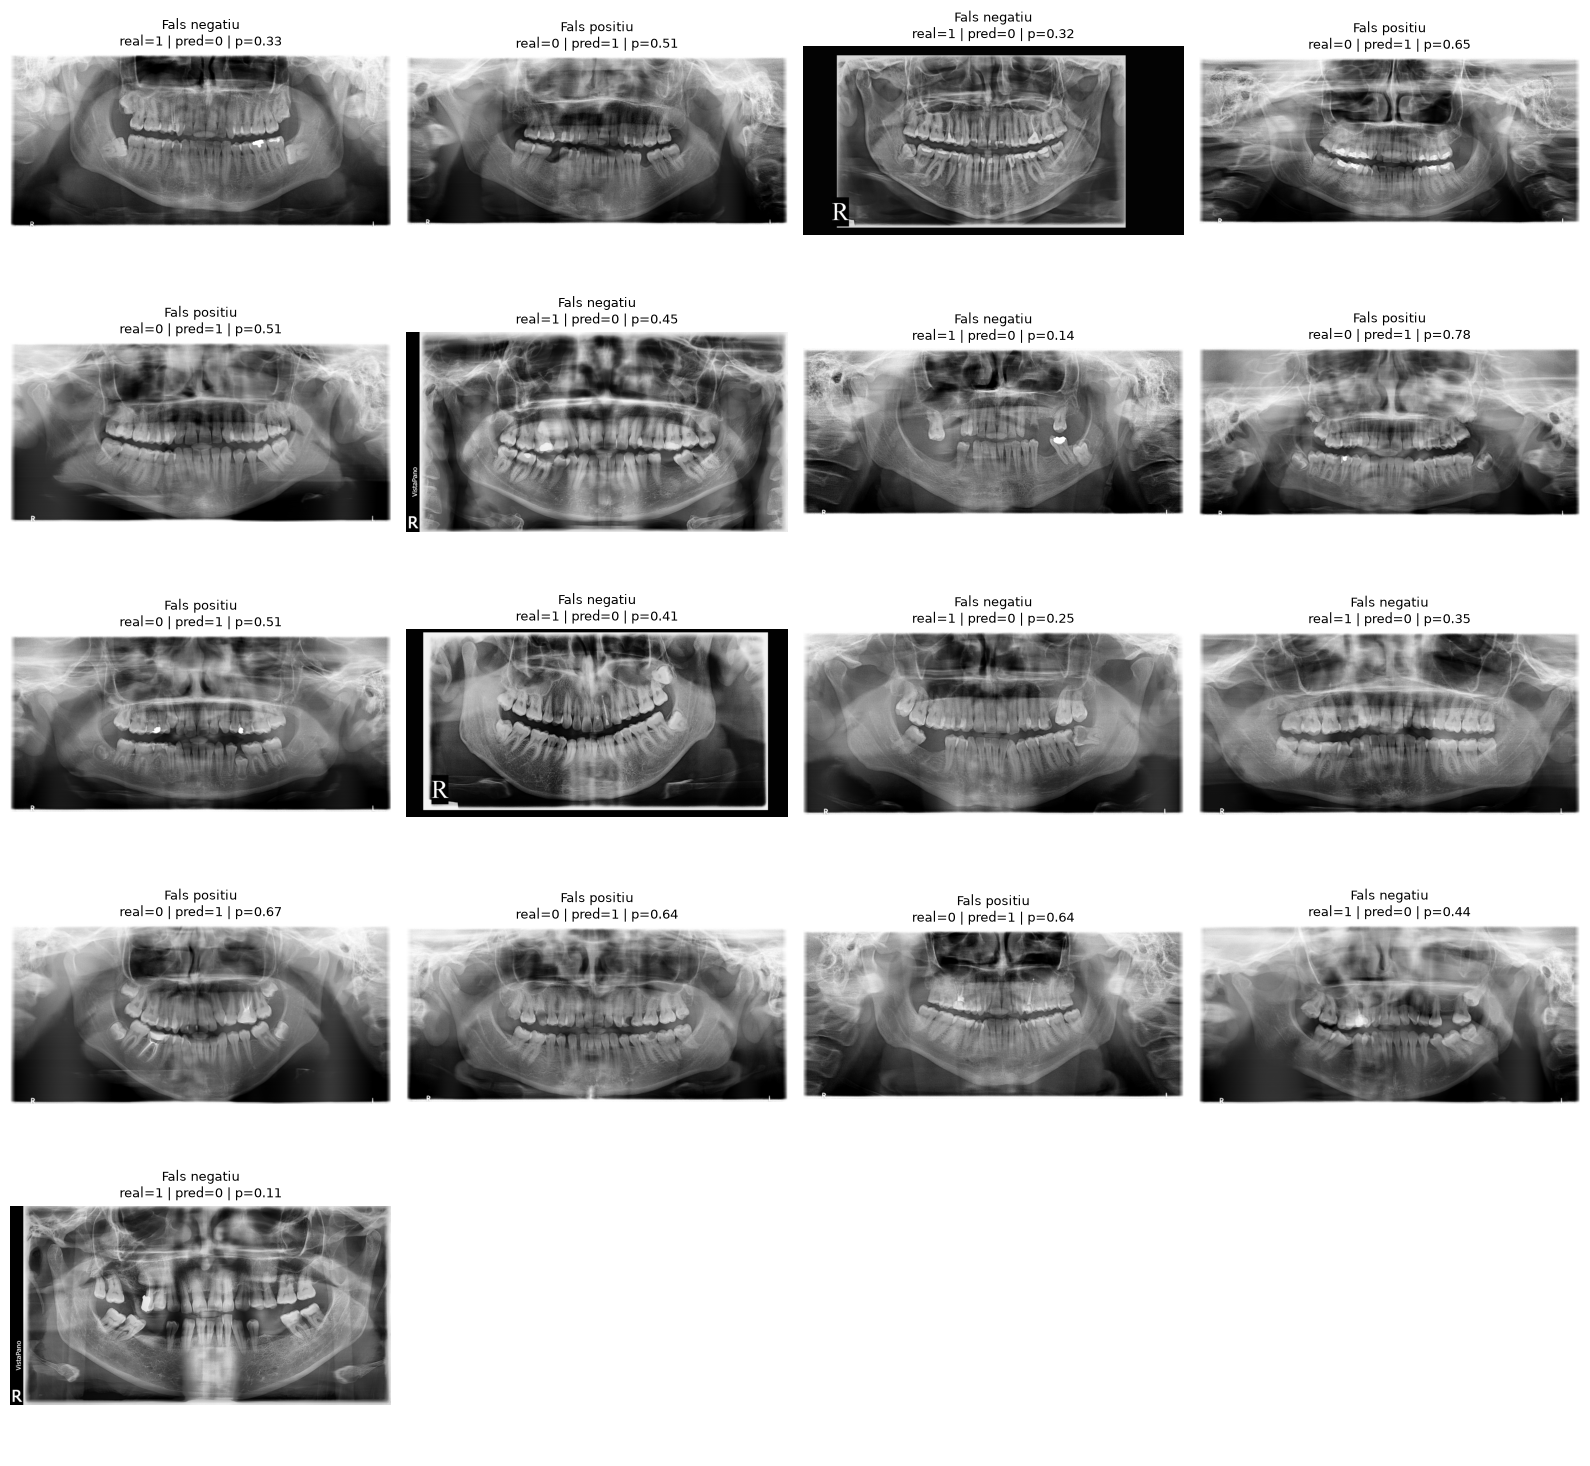

In [21]:
import math

n_columns = 4
n_rows = math.ceil(len(errors_df) / n_columns)

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(16, 3 * n_rows)
)

axes = axes.flatten()

for ax, (_, row) in zip(axes, errors_df.iterrows()):
    image = Image.open(
        val_images_dir / row["file_name"]
    )

    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"{row['error_type']}\n"
        f"real={row['has_impacted']} | "
        f"pred={row['prediction']} | "
        f"p={row['prob_impacted']:.2f}",
        fontsize=9
    )
    ax.axis("off")

for ax in axes[len(errors_df):]:
    ax.axis("off")

plt.tight_layout()
plt.show()